# Customer Churn Prediction Using Machine Learning

**University of Lahore – Faculty of Information Technology**  
**Course:** Artificial Intelligence  
**Dataset:** `WA_Fn-UseC_-Telco-Customer-Churn.xlsx`

## Objective
The objective of this notebook is to build a complete machine learning system that predicts whether a telecom customer will **Churn (Yes)** or **Not Churn (No)**.

The notebook covers:
1. Data loading and understanding
2. Data preprocessing
3. Exploratory Data Analysis (EDA)
4. Feature engineering and encoding
5. Training and testing
6. Model evaluation
7. Sample customer prediction

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay
)

## 1. Data Loading

The Excel dataset is loaded using Pandas. The Excel file is in the same folder as this notebook.

In [10]:
file_name = "WA_Fn-UseC_-Telco-Customer-Churn (1).csv"

df = pd.read_csv(file_name)

print("Dataset loaded successfully.")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

df.head()

Dataset loaded successfully.
Number of rows: 7043
Number of columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [11]:
print("Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nBasic Statistics:")
display(df.describe(include="all").T)

Shape: (7043, 21)

Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data Types:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

Basic Statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Data Preprocessing

Before training a model, the data must be checked for:
- Missing values
- Duplicate records
- Incorrect data types
- Unnecessary columns
- Invalid or inconsistent values

In [12]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nUnique values in important columns:")
print("Churn:", df["Churn"].unique())
print("Contract:", df["Contract"].unique())
print("InternetService:", df["InternetService"].unique())

Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate rows: 0

Unique values in important columns:
Churn: <StringArray>
['No', 'Yes']
Length: 2, dtype: str
Contract: <StringArray>
['Month-to-month', 'One year', 'Two year']
Length: 3, dtype: str
InternetService: <StringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str


### Cleaning `TotalCharges`

In this dataset, `TotalCharges` can contain blank spaces. Pandas may therefore read it as an object/string column instead of a numeric column.

We convert blank values to missing values and then convert the column to numeric.

In [13]:
df["TotalCharges"] = df["TotalCharges"].replace(" ", np.nan)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Missing values after converting TotalCharges:")
print(df["TotalCharges"].isnull().sum())

print("\nData types after conversion:")
print(df.dtypes)

Missing values after converting TotalCharges:
11

Data types after conversion:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object


### Handling Missing Values

The missing `TotalCharges` values are mainly associated with customers who have very low/zero tenure. Since `TotalCharges` is an important numerical feature, the missing values are filled with the median.

The median is used because it is less affected by unusually large values than the mean.

In [14]:
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())

print("Missing values after cleaning:")
print(df.isnull().sum().sum())

print("Duplicate rows:", df.duplicated().sum())

Missing values after cleaning:
0
Duplicate rows: 0


### Removing the Unnecessary Customer ID

`customerID` is only an identifier. It does not describe customer behavior and should not be used as a predictive feature.

In [15]:
df = df.drop("customerID", axis=1)

print("New shape:", df.shape)
df.head()

New shape: (7043, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Exploratory Data Analysis

EDA helps us understand the distribution of churn and relationships between churn and customer characteristics.

Churn Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


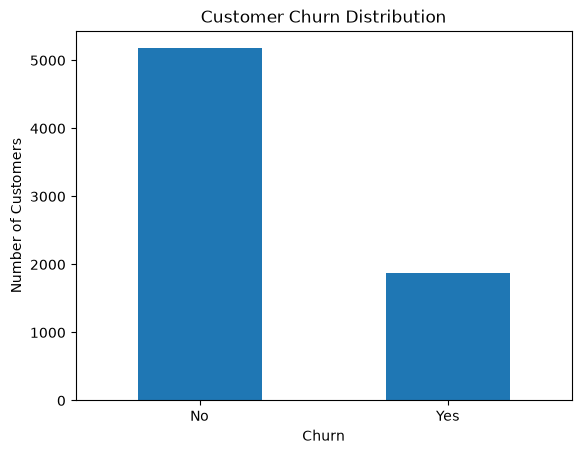

In [16]:
print("Churn Distribution:")
print(df["Churn"].value_counts())

print("\nChurn Percentage:")
print(df["Churn"].value_counts(normalize=True) * 100)

df["Churn"].value_counts().plot(kind="bar")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

Churn                  No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.730482  11.269518
Two year        97.168142   2.831858


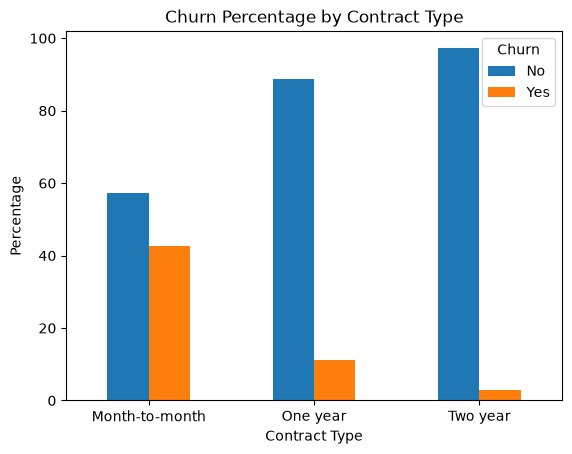

In [17]:
# Churn by contract type
contract_churn = pd.crosstab(df["Contract"], df["Churn"], normalize="index") * 100
print(contract_churn)

contract_churn.plot(kind="bar")
plt.title("Churn Percentage by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.show()

Churn                   No        Yes
InternetService                      
DSL              81.040892  18.959108
Fiber optic      58.107235  41.892765
No               92.595020   7.404980


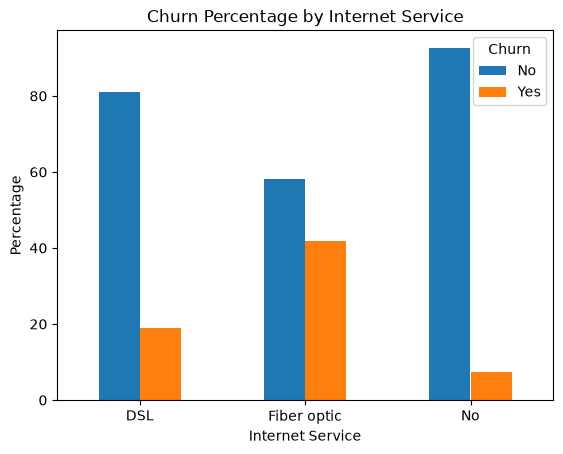

In [18]:
# Churn by internet service
internet_churn = pd.crosstab(df["InternetService"], df["Churn"], normalize="index") * 100
print(internet_churn)

internet_churn.plot(kind="bar")
plt.title("Churn Percentage by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.show()

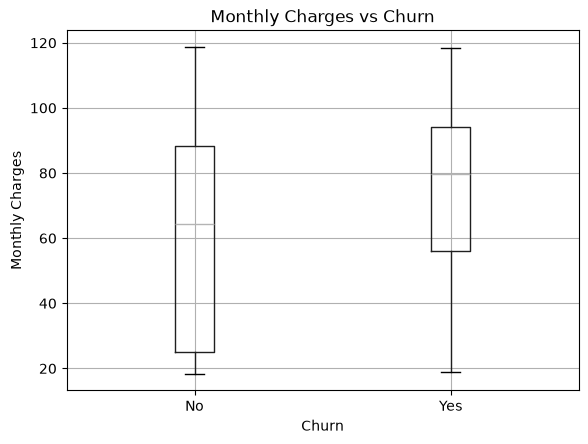

In [19]:
# Monthly charges by churn
df.boxplot(column="MonthlyCharges", by="Churn")
plt.title("Monthly Charges vs Churn")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.show()

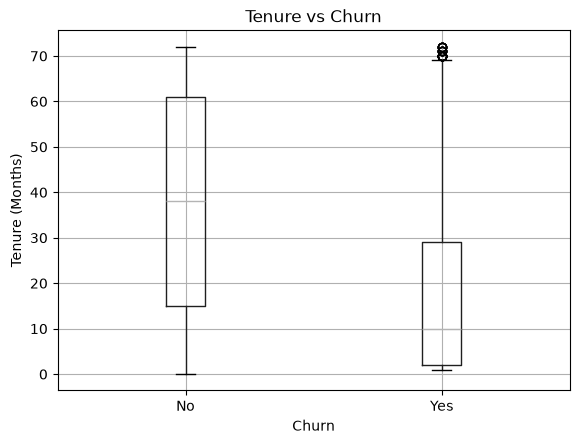

In [20]:
# Tenure by churn
df.boxplot(column="tenure", by="Churn")
plt.title("Tenure vs Churn")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")
plt.show()

### EDA Observations

The exact observations should be based on the outputs above. Common patterns that may appear in this dataset include:

- Customers with shorter tenure can show higher churn.
- Contract type can have a strong relationship with churn.
- Monthly charges can differ between customers who churn and those who remain.
- Internet service type can also be associated with different churn rates.

These observations are descriptive patterns in the dataset and do not by themselves prove causation.

## 4. Feature Engineering and Encoding

The target variable is `Churn`.

- `X` contains the input features.
- `y` contains the target.
- `Yes` is converted to 1.
- `No` is converted to 0.

Categorical columns are converted to numerical values using one-hot encoding with Pandas.

In [21]:
# Separate input features and target
X = df.drop("Churn", axis=1)
y = df["Churn"].map({"No": 0, "Yes": 1})

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget values:")
print(y.value_counts())

X shape: (7043, 19)
y shape: (7043,)

Target values:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [22]:
# Convert categorical features into numerical columns
X = pd.get_dummies(X, drop_first=True)

print("Encoded X shape:", X.shape)
print("\nEncoded columns:")
print(X.columns.tolist())

Encoded X shape: (7043, 30)

Encoded columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'gender_Male', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes', 'MultipleLines_No phone service', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_No internet service', 'OnlineSecurity_Yes', 'OnlineBackup_No internet service', 'OnlineBackup_Yes', 'DeviceProtection_No internet service', 'DeviceProtection_Yes', 'TechSupport_No internet service', 'TechSupport_Yes', 'StreamingTV_No internet service', 'StreamingTV_Yes', 'StreamingMovies_No internet service', 'StreamingMovies_Yes', 'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']


## 5. Training and Testing

The dataset is divided into:
- **80% training data** – used to train the models
- **20% testing data** – used to evaluate the models

`stratify=y` keeps the proportion of churn and non-churn customers similar in both sets.

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5634, 30)
Testing data: (1409, 30)


### Feature Scaling

Logistic Regression benefits from features being on comparable scales. We standardize the numerical values using `StandardScaler`.

Random Forest does not require scaling, so it will use the original encoded features.

In [24]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 6. Model 1 – Logistic Regression

Logistic Regression is a common classification algorithm for binary outcomes such as Churn = Yes/No.

In [25]:
logistic_model = LogisticRegression(max_iter=1000, random_state=42)

logistic_model.fit(X_train_scaled, y_train)

logistic_pred = logistic_model.predict(X_test_scaled)

print("Logistic Regression trained successfully.")

Logistic Regression trained successfully.


## 7. Model 2 – Random Forest

Random Forest combines multiple decision trees and can model non-linear relationships between customer features and churn.

In [26]:
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

random_forest_model.fit(X_train, y_train)

random_forest_pred = random_forest_model.predict(X_test)

print("Random Forest trained successfully.")

Random Forest trained successfully.


## 8. Model Evaluation

The assignment requires:
- Accuracy
- Precision
- Recall
- F1-Score
- Confusion Matrix

Logistic Regression
----------------------------------------
Accuracy : 0.807
Precision: 0.6584
Recall   : 0.5668
F1-Score : 0.6092

Confusion Matrix:
[[925 110]
 [162 212]]


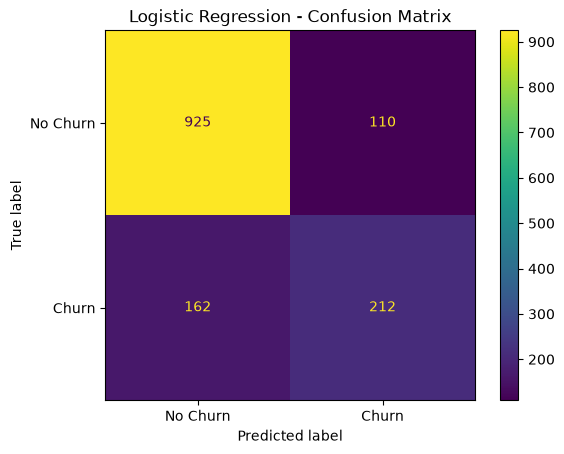

Random Forest
----------------------------------------
Accuracy : 0.7864
Precision: 0.6237
Recall   : 0.492
F1-Score : 0.5501

Confusion Matrix:
[[924 111]
 [190 184]]


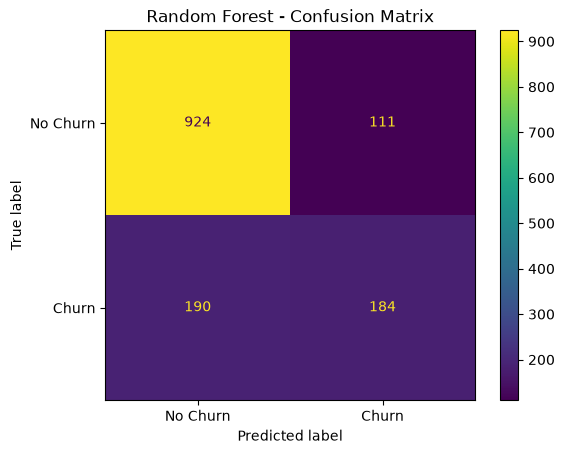

In [27]:
def evaluate_model(name, y_true, y_pred):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)

    print(name)
    print("-" * 40)
    print("Accuracy :", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1-Score :", round(f1, 4))

    cm = confusion_matrix(y_true, y_pred)
    print("\nConfusion Matrix:")
    print(cm)

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Churn", "Churn"]
    ).plot()

    plt.title(name + " - Confusion Matrix")
    plt.show()

    return [accuracy, precision, recall, f1]

logistic_scores = evaluate_model(
    "Logistic Regression",
    y_test,
    logistic_pred
)

random_forest_scores = evaluate_model(
    "Random Forest",
    y_test,
    random_forest_pred
)

In [28]:
results = pd.DataFrame(
    [logistic_scores, random_forest_scores],
    columns=["Accuracy", "Precision", "Recall", "F1-Score"],
    index=["Logistic Regression", "Random Forest"]
)

results

,Accuracy,Precision,Recall,F1-Score
Logistic Regression,0.806955,0.658385,0.566845,0.609195
Random Forest,0.786373,0.623729,0.491979,0.550075


### Model Comparison

The table above provides an objective comparison of the two models.

For churn prediction, **Recall** is particularly important because missing a customer who is actually going to churn can prevent the company from taking retention action.

However, the final model should be selected using the actual evaluation results rather than assuming one algorithm will always perform better.

In [29]:
# Select the model with the higher F1-score.
if random_forest_scores[3] > logistic_scores[3]:
    final_model_name = "Random Forest"
    final_model = random_forest_model
    final_scaler = None
else:
    final_model_name = "Logistic Regression"
    final_model = logistic_model
    final_scaler = scaler

print("Selected final model:", final_model_name)

Selected final model: Logistic Regression


## 9. Application / Prediction

The following example shows how customer information can be passed to the final model.

The example values are only sample customer information. The same format can be used for real customers.

In [30]:
sample_customer = pd.DataFrame([{
    "gender": "Male",
    "SeniorCitizen": 0,
    "Partner": "No",
    "Dependents": "No",
    "tenure": 5,
    "PhoneService": "Yes",
    "MultipleLines": "No",
    "InternetService": "Fiber optic",
    "OnlineSecurity": "No",
    "OnlineBackup": "No",
    "DeviceProtection": "No",
    "TechSupport": "No",
    "StreamingTV": "No",
    "StreamingMovies": "No",
    "Contract": "Month-to-month",
    "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check",
    "MonthlyCharges": 80.00,
    "TotalCharges": 400.00
}])

sample_encoded = pd.get_dummies(sample_customer)

# Make the sample have exactly the same columns as the training data.
sample_encoded = sample_encoded.reindex(columns=X.columns, fill_value=0)

if final_model_name == "Logistic Regression":
    sample_input = final_scaler.transform(sample_encoded)
else:
    sample_input = sample_encoded

prediction = final_model.predict(sample_input)[0]

if prediction == 1:
    print("Prediction: Churn")
else:
    print("Prediction: No Churn")

Prediction: Churn


## 10. Conclusion

This project implemented a complete customer churn prediction pipeline.

The dataset was loaded and examined, data quality issues were checked, `TotalCharges` was converted to a numerical format, missing values were handled, and the unnecessary customer ID was removed.

Exploratory analysis was then used to study churn patterns involving variables such as tenure, contract type, internet service, and monthly charges.

Two classification models were trained:
1. Logistic Regression
2. Random Forest

Their Accuracy, Precision, Recall, F1-Score, and Confusion Matrices were compared. The final model was selected using the F1-Score from the test results.

A sample customer was then passed through the same preprocessing process and the final model produced a **Churn** or **No Churn** prediction.

### Limitations

- The model is trained on historical data, so future customer behavior may differ.
- A prediction is not a guarantee that a customer will actually leave.
- Other useful business information may not be present in the dataset.
- The model's performance can change when applied to a different telecom company or a different population.

### Business Use

A telecom company could use a churn prediction system to identify customers who may be at higher risk of leaving. The company could then investigate appropriate retention actions, such as improving service or offering relevant customer support.